# Задача 4.2
# Рассадка мужчин и женщин

## Условие
Пять различных мужчин и пять различных женщин случайно занимают 10 мест в ряд. $A$ — никакие две женщины не сидят рядом; $B$ — все мужчины сидят рядом.

## Теория с нуля и решение вручную
### 1. Перестановки
Поставить $n$ различных людей в ряд можно $n!$ способами: для первого места есть $n$ кандидатов, для второго $n-1$ и так далее. Все $10!$ рассадок считаются равновозможными. Перестановки используются, когда порядок важен; сочетания — когда выбирают только набор.

### 2. Событие A и метод промежутков
Сначала расставим мужчин: $5!$ вариантов. Получится шесть промежутков: до первого мужчины, четыре между соседними и после последнего. Чтобы женщины не соседствовали, выбираем пять различных промежутков из шести и ставим туда по одной женщине. Порядок женщин задаёт ещё $5!$ вариантов:
$$P(A)=\frac{5!\binom65 5!}{10!}=\frac6{\binom{10}5}=\frac1{42}.$$
Упрощённый подсчёт: набор из пяти женских мест равновероятно выбирается из $\binom{10}5=252$ наборов; подходящих наборов шесть.

### 3. Событие B и метод блока
Объединим пятерых мужчин в один блок. Теперь переставляем шесть объектов: блок и пять женщин, всего $6!$ вариантов. Внутри блока мужчин можно переставить $5!$ способами:
$$P(B)=\frac{6!5!}{10!}=\frac1{42}\approx0.02380952.$$
Равенство вероятностей не означает совпадения событий. Например, при сплошном мужском блоке женщины могут сидеть рядом.

### 4. Переход к коду
Перемешиваем номера 0…9; номера 0…4 обозначают мужчин. Для $A$ проверяем пять женских позиций через соседние столбцы: ни одна пара соседних мест не должна быть женской. Для $B$ крайние позиции мужчин должны различаться на 4, потому что между пятью подряд стоящими местами четыре промежутка. `argsort` сортирует случайные непрерывные метки и тем самым даёт равновероятную перестановку; совпадения меток в математической модели имеют вероятность ноль.

### Как связаны теория и эксперимент

Один опыт — одно полное выполнение условия задачи. Повторяем его независимо $N$ раз. Индикатор $I_k(A)$ равен 1, если событие произошло в опыте $k$, и 0 иначе. Тогда
$$N_A=\sum_{k=1}^{N}I_k(A),\qquad \widehat p_N(A)=\frac{N_A}{N}.$$
По закону больших чисел частота приближается к вероятности при росте числа опытов. Она может колебаться и временно удаляться от ответа: монотонное приближение не обещается. Вероятность — характеристика модели, частота — результат конкретного эксперимента.

Для условной вероятности оставляем только опыты, в которых произошло условие $B$:
$$P(A\mid B)=\frac{P(A\cap B)}{P(B)},\qquad \widehat p(A\mid B)=\frac{N_{A\cap B}}{N_B}.$$
Знаменатель здесь $N_B$, а не общее $N$. Если $N_B=0$, оценка пока не определена.

Приближённая стандартная ошибка частоты равна $\sqrt{\widehat p(1-\widehat p)/m}$, где $m=N$ для обычной вероятности и $m=N_B$ для условной. При достаточно большом числе успехов и неудач ориентировочный 95-процентный интервал имеет вид $\widehat p\pm1.96\sqrt{\widehat p(1-\widehat p)/m}$. Это приближение, а не гарантия для каждого запуска. Для редкого события важен именно ожидаемый счётчик $NP(A)$.

### Что делают библиотеки и общие строки кода

`numpy` хранит результаты опытов в массивах, генерирует случайные числа и считает суммы. Булев массив содержит `True` или `False`; при подсчёте это соответственно 1 и 0. `&` означает «и», `|` — «или», `~` — «не»; каждое сравнение берём в скобки. `axis=1` означает действие внутри строки, то есть внутри одного опыта. Векторные операции повторяют одну и ту же понятную формулу сразу для всех опытов.

`matplotlib.pyplot` рисует график накопленной частоты. Стандартные модули `math` и `fractions` дают элементарные функции, число сочетаний `comb` и точные дроби `Fraction`. Они не выбирают метод решения за нас. В коде используются только эти библиотеки; `scipy` не требуется.

`rng = np.random.default_rng(2026)` создаёт генератор с фиксированным начальным состоянием: повторный запуск даёт тот же эксперимент. Это нужно для воспроизводимости. `rng.random(N)` даёт $N$ независимых равномерных чисел от 0 до 1, а `rng.uniform(a,b,N)` — от $a$ до $b$. Концы непрерывных интервалов имеют вероятность ноль.

Общая функция `report` буквально реализует формулы выше: `np.cumsum` последовательно накапливает единицы, после чего мы делим число успехов на число допустимых опытов. Пунктир — теоретическое значение, если оно известно. На графике показана часть точек для читаемости; в расчёт входят **все** опыты. Интервал выводится только как ориентир точности моделирования.

A: женщины не соседствуют: успехов 3681, знаменатель 150000
  частота = 0.02454000; ориентир 95%: [0.02375702; 0.02532298]
  теория = 0.02380952; разность = +0.00073048


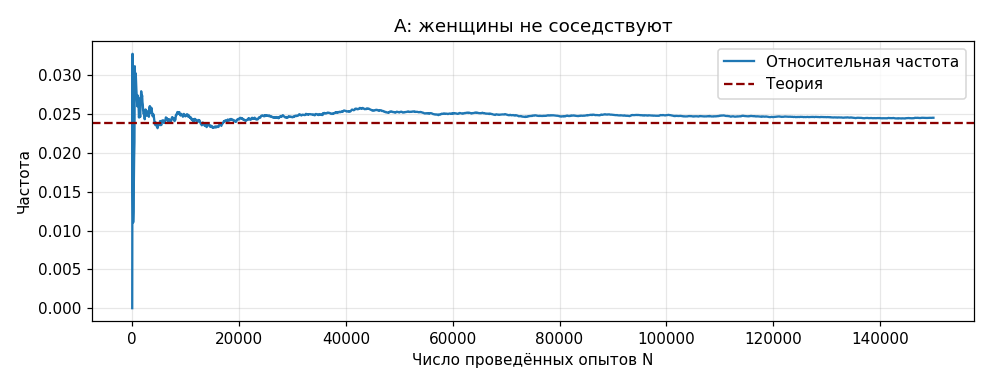

B: мужчины образуют один блок: успехов 3584, знаменатель 150000
  частота = 0.02389333; ориентир 95%: [0.02312048; 0.02466619]
  теория = 0.02380952; разность = +0.00008381


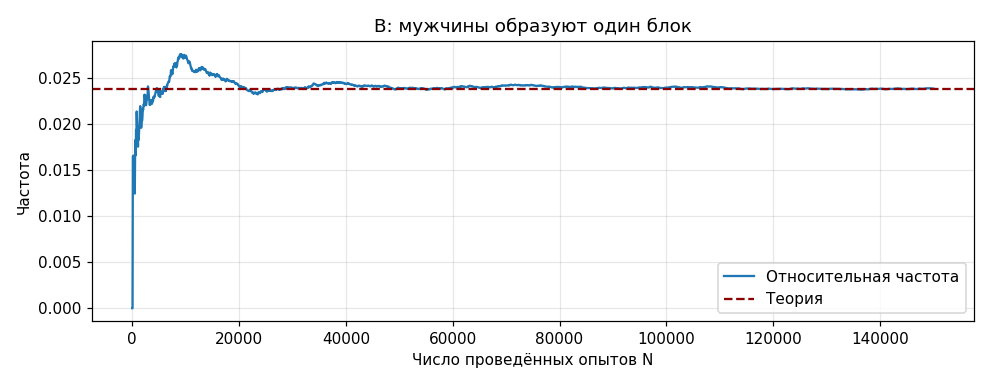

In [1]:
import math
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt

# Начальное состояние генератора фиксируем для повторяемого результата.
rng = np.random.default_rng(2026)

def report(event, name, exact=None, condition=None):
    """Частота события, а при condition — условная частота из теории."""
    event = np.asarray(event, dtype=bool)
    if condition is None:
        condition = np.ones(len(event), dtype=bool)
    # В условном случае считаем успех только вместе с выполнением условия.
    successes = np.cumsum(event & condition)
    eligible = np.cumsum(condition)
    frequency = np.full(len(event), np.nan)
    np.divide(successes, eligible, out=frequency, where=(eligible > 0))
    estimate = frequency[-1]
    m = int(eligible[-1])
    error = math.sqrt(estimate * (1 - estimate) / m) if m else float('nan')
    print(f'{name}: успехов {successes[-1]}, знаменатель {m}')
    print(f'  частота = {estimate:.8f}; ориентир 95%: '
          f'[{max(0, estimate - 1.96 * error):.8f}; '
          f'{min(1, estimate + 1.96 * error):.8f}]')
    if exact is not None:
        print(f'  теория = {float(exact):.8f}; разность = {estimate-float(exact):+.8f}')
    # Накопленные суммы рассчитаны по всем опытам; прореживаем лишь рисунок.
    indices = np.unique(np.linspace(0, len(event)-1, min(2500, len(event))).astype(int))
    plt.figure(figsize=(9, 3.5))
    plt.plot(indices+1, frequency[indices], label='Относительная частота')
    if exact is not None:
        plt.axhline(float(exact), color='darkred', linestyle='--', label='Теория')
    plt.xlabel('Число проведённых опытов N')
    plt.ylabel('Частота')
    plt.title(name)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
    return estimate

N = 150_000
order = rng.random((N, 10)).argsort(axis=1)
men = order < 5
women = ~men
# Теория 4: ищем хотя бы одну соседнюю пару женщин, затем отрицаем.
A = ~np.any(women[:, :-1] & women[:, 1:], axis=1)
positions = np.arange(10)
first_man = np.min(np.where(men, positions, 10), axis=1)
last_man = np.max(np.where(men, positions, -1), axis=1)
B = last_man-first_man == 4
report(A, 'A: женщины не соседствуют', Fraction(1, 42))
report(B, 'B: мужчины образуют один блок', Fraction(1, 42))
